# Phase 2.2 — Exploratory Data Analysis: Training Phenotype & Trait Data (`2014–2025`)

**Project:** G2F Maize Yield Prediction 2026  
**Dataset:** `1_Training_Trait_Data_2014_2025.csv`  
**Prediction Target:** `Yield_Mg_ha` (maize grain yield in Mg/ha adjusted to 15.5% moisture)

## Scope & Guardrails
This notebook performs **strictly read-only exploratory data analysis (EDA)** on the raw training trait table before any cleaning, merging, feature engineering, or modeling:
- Original data files are never modified.
- No rows are dropped, imputed, or aggregated into a modeling dataset.
- Outliers are quantified and inspected, **not** removed or assumed invalid.
- Official documented definitions are explicitly separated from inferred interpretations.

## Notebook Structure
1. Reproducible Data Loading & Memory Profiling
2. Dataset Structure, Data Types & Column Meanings
3. Missing Data & Sentinel Value Audit
4. Target Variable Analysis (`Yield_Mg_ha`)
5. Observation Granularity, Experimental Replicates & Duplicate Audit
6. Temporal (2014–2025) & Environmental / Hybrid Variability Analysis
7. Preliminary Data Leakage Assessment
8. Summary of Confirmed Findings & Open Questions

## 1. Reproducible Data Loading

### Why this matters for machine learning
Hardcoding user-specific paths (e.g., `C:\Users\...`) breaks reproducibility across machines and collaborators. Resolving paths relative to the repository root ensures anyone cloning the project can re-run this analysis identically.

We also follow two defensive CSV-loading practices:
1. **Inspect the header and first 5 rows before loading the full file** to verify delimiters, encodings, and column layout without risking a surprise memory spike.
2. **Use Pandas' default C CSV engine (`engine="c"`)** rather than assuming `engine="pyarrow"` supports every option (such as `nrows` or `low_memory=False`). Passing `low_memory=False` on the full load ensures consistent column dtype inference across the entire file.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start: Path) -> Path:
    """Walk upward from start until the repository root (containing README.md and data/) is found."""
    for candidate in [start, *start.parents]:
        if (candidate / "README.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate project root containing README.md and data/.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
TRAIT_REL_PATH = Path(
    "data/raw/training/Training_Data-20261123T123657Z-1-001/Training_Data/1_Training_Trait_Data_2014_2025.csv"
)
TRAIT_PATH = PROJECT_ROOT / TRAIT_REL_PATH
FIGURES_DIR = PROJECT_ROOT / "reports/figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

assert TRAIT_PATH.is_file(), f"Expected dataset not found at {TRAIT_REL_PATH}"
print(f"Relative dataset path : {TRAIT_REL_PATH.as_posix()}")
print(f"File size on disk     : {TRAIT_PATH.stat().st_size / (1024 ** 2):.2f} MB ({TRAIT_PATH.stat().st_size:,} bytes)")
print(f"Figures output folder : {FIGURES_DIR.relative_to(PROJECT_ROOT).as_posix()}")

Relative dataset path : data/raw/training/Training_Data-20261123T123657Z-1-001/Training_Data/1_Training_Trait_Data_2014_2025.csv
File size on disk     : 35.54 MB (37,267,047 bytes)
Figures output folder : reports/figures


In [2]:
# Step 1a: Inspect the CSV header and first 5 sample rows before loading the full file.
# Note: Output of this cell contains raw competition records and is cleared prior to Git commits.
preview_df = pd.read_csv(TRAIT_PATH, engine="c", nrows=5)
print(f"Preview shape: {preview_df.shape}")
print("Columns:", list(preview_df.columns))
display(preview_df)

In [3]:
# Step 1b: Load the complete trait dataset using Pandas' C engine with low_memory=False
# to preserve original column names and values while avoiding mixed-dtype chunk warnings.
t0 = time.perf_counter()
df = pd.read_csv(TRAIT_PATH, engine="c", low_memory=False)
load_seconds = time.perf_counter() - t0

mem_bytes_deep = int(df.memory_usage(deep=True).sum())
mem_mb_deep = mem_bytes_deep / (1024 ** 2)
mem_mb_shallow = df.memory_usage(deep=False).sum() / (1024 ** 2)

print(f"Loaded shape          : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Load time (C engine)  : {load_seconds:.3f} seconds")
print(f"Memory usage (deep)   : {mem_mb_deep:.2f} MB ({mem_bytes_deep:,} bytes)")
print(f"Memory usage (shallow): {mem_mb_shallow:.2f} MB")

Loaded shape          : 203,185 rows x 26 columns
Load time (C engine)  : 0.317 seconds
Memory usage (deep)   : 58.65 MB (61,503,305 bytes)
Memory usage (shallow): 58.65 MB


## 2. Dataset Structure, Data Types & Column Meanings

### Why this matters for machine learning
Knowing exact row/column counts, inferred types, and unique value counts (cardinality) reveals:
- Which columns are identifiers vs. categorical factors vs. continuous measurements.
- Whether numeric columns were accidentally parsed as strings due to formatting glitches or sentinel text.
- How large one-hot encodings or entity embedding tables would be in later modeling phases.

In [4]:
structure_df = pd.DataFrame({
    "column": df.columns,
    "inferred_dtype": df.dtypes.astype(str).values,
    "non_missing": df.notna().sum().values,
    "nunique_non_null": [int(df[c].nunique(dropna=True)) for c in df.columns],
    "nunique_incl_na": [int(df[c].nunique(dropna=False)) for c in df.columns],
    "memory_mb_deep": [round(df[c].memory_usage(deep=True) / (1024 ** 2), 3) for c in df.columns],
})
print(f"Total rows: {len(df):,} | Total columns: {df.shape[1]}")
print(structure_df.to_string(index=False))

Total rows: 203,185 | Total columns: 26
              column inferred_dtype  non_missing  nunique_non_null  nunique_incl_na  memory_mb_deep
                 Env            str       203185               321              321           3.314
                Year          int64       203185                12               12           1.550
      Field_Location            str       203185                46               46           2.339
          Experiment            str       203185                12               12           4.487
           Replicate          int64       203185                 4                4           1.550
               Block          int64       203185                50               50           1.550
                Plot          int64       203185              2588             2588           1.550
               Range        float64       183826               124              125           1.550
                Pass        float64       183736            

In [5]:
# Local inspection of the first five rows of the loaded DataFrame.
# Note: Output of this cell contains raw competition records and is cleared prior to Git commits.
display(df.head(5))

### Column Definitions (Verified vs. Inferred)

> **Documentation Boundary:** No local data dictionary file was present inside `data/raw/training/`. Only `Yield_Mg_ha` is **verified directly from the official 2026 G2F EvalAI competition page**; all other column meanings below are **inferred interpretations** based on standard agronomic and G2F naming conventions and should be confirmed against official G2F documentation when available.

| Column | Documentation Status | Meaning / Interpretation |
| :--- | :--- | :--- |
| `Env` | Inferred | Unique field trial environment identifier, typically encoding location and growing year (e.g., `<Field_Location>_<Year>`). |
| `Year` | Inferred | Calendar growing season year of the field trial (`2014`–`2025`). |
| `Field_Location` | Inferred | Field trial site/location code (state/region and cooperator site abbreviation). |
| `Experiment` | Inferred | G2F experiment or trial series identifier within a season/location. |
| `Replicate` | Inferred | Experimental replication number within a trial design. |
| `Block` | Inferred | Experimental block number within a replicate/trial (e.g., randomized block design). |
| `Plot` | Inferred | Individual field plot identifier within a trial/replicate/block. |
| `Range` | Inferred | Spatial grid coordinate (row/range axis) of a plot in the field layout. |
| `Pass` | Inferred | Spatial grid coordinate (column/pass axis) of a plot in the field layout. |
| `Hybrid` | Inferred | Standardized maize hybrid identifier (typically `Parent1/Parent2` or commercial hybrid name). |
| `Hybrid_orig_name` | Inferred | Original unstandardized hybrid name as recorded in the field trial. |
| `Hybrid_Parent1` | Inferred | First parental inbred line identifier of the hybrid cross. |
| `Hybrid_Parent2` | Inferred | Second parental inbred line identifier (often tester line) of the hybrid cross. |
| `Plot_Area_ha` | Inferred | Harvested or planted plot area in hectares (`ha`). |
| `Date_Planted` | Inferred | Calendar planting date of the plot/trial. |
| `Date_Harvested` | Inferred | Calendar harvest date of the plot/trial. |
| `Stand_Count_plants` | Inferred | Count of emerged/established maize plants per plot. |
| `Pollen_DAP_days` | Inferred | Days after planting (`DAP`) to anthesis / pollen shed (male flowering time). |
| `Silk_DAP_days` | Inferred | Days after planting (`DAP`) to silking (female flowering time). |
| `Plant_Height_cm` | Inferred | Measured maize plant height in centimeters (`cm`). |
| `Ear_Height_cm` | Inferred | Measured ear insertion height in centimeters (`cm`). |
| `Root_Lodging_plants` | Inferred | Count of root-lodged plants in the plot. |
| `Stalk_Lodging_plants` | Inferred | Count of stalk-lodged plants in the plot. |
| `Yield_Mg_ha` | **Verified (EvalAI)** | **Prediction target:** absolute maize grain yield in megagrams per hectare (`Mg/ha`), adjusted to `15.5%` moisture. |
| `Grain_Moisture` | Inferred | Grain moisture content (%) measured at harvest. |
| `Twt_kg_m3` | Inferred | Grain test weight (bulk density) in kilograms per cubic meter (`kg/m^3`), measured at harvest. |

## 3. Missing Data & Sentinel Value Analysis

### Why this matters for machine learning
Missing data is rarely random in agricultural field trials — an entire location may skip measuring lodging or flowering dates, or a severe weather event may wipe out harvest yield for a whole environment.
- **Missing targets (`Yield_Mg_ha`):** Rows without a valid target cannot directly compute supervised regression loss and must be understood by year and environment before deciding how to handle them.
- **Sentinel strings / numeric codes:** Sometimes missing values are encoded as `"NA"`, `"."`, `"-999"`, or `0` instead of `NaN`. Here we **audit** for candidate sentinels without replacing anything.

In [6]:
missing_df = pd.DataFrame({
    "column": df.columns,
    "non_missing_count": df.notna().sum().values,
    "missing_count": df.isna().sum().values,
    "missing_pct": (df.isna().mean() * 100).round(4).values,
}).sort_values("missing_count", ascending=False).reset_index(drop=True)

print("=== MISSING DATA SUMMARY (ALL 26 COLUMNS) ===")
print(missing_df.to_string(index=False))

=== MISSING DATA SUMMARY (ALL 26 COLUMNS) ===
              column  non_missing_count  missing_count  missing_pct
 Root_Lodging_plants             131814          71371      35.1261
Stalk_Lodging_plants             146015          57170      28.1369
       Silk_DAP_days             155490          47695      23.4737
     Pollen_DAP_days             157946          45239      22.2649
           Twt_kg_m3             163690          39495      19.4380
     Plant_Height_cm             176437          26748      13.1644
       Ear_Height_cm             177971          25214      12.4094
  Stand_Count_plants             180711          22474      11.0609
                Pass             183736          19449       9.5721
               Range             183826          19359       9.5278
      Grain_Moisture             192693          10492       5.1638
         Yield_Mg_ha             192974          10211       5.0255
      Hybrid_Parent2             200639           2546       1.2530
  

In [7]:
# Investigate missing Yield_Mg_ha across Years and Environments
target_col = "Yield_Mg_ha"
missing_by_year = (
    df.groupby("Year")[target_col]
    .agg(
        total_rows="size",
        valid_yield="count",
        missing_yield=lambda s: int(s.isna().sum()),
    )
    .assign(missing_pct=lambda d: (d["missing_yield"] / d["total_rows"] * 100).round(2))
)
print("=== MISSING Yield_Mg_ha BY YEAR ===")
print(missing_by_year.to_string())

missing_by_env = (
    df.groupby("Env")[target_col]
    .agg(
        total_rows="size",
        valid_yield="count",
        missing_yield=lambda s: int(s.isna().sum()),
    )
    .assign(missing_pct=lambda d: (d["missing_yield"] / d["total_rows"] * 100).round(2))
    .sort_values(["missing_pct", "missing_yield"], ascending=False)
)

n_env_total = len(missing_by_env)
n_env_zero_miss = int((missing_by_env["missing_yield"] == 0).sum())
n_env_partial = int(((missing_by_env["missing_yield"] > 0) & (missing_by_env["valid_yield"] > 0)).sum())
n_env_all_miss = int((missing_by_env["valid_yield"] == 0).sum())
n_env_gt50 = int((missing_by_env["missing_pct"] > 50).sum())

print(f"\n=== MISSING Yield_Mg_ha ACROSS ENVIRONMENTS (n={n_env_total}) ===")
print(f"Environments with 0% missing yield       : {n_env_zero_miss}")
print(f"Environments with partial missing yield  : {n_env_partial}")
print(f"Environments with 100% missing yield     : {n_env_all_miss}")
print(f"Environments with >50% missing yield     : {n_env_gt50}")
print("\nTop 15 environments by missing yield percentage:")
print(missing_by_env.head(15).to_string())

=== MISSING Yield_Mg_ha BY YEAR ===
      total_rows  valid_yield  missing_yield  missing_pct
Year                                                     
2014       12675        11593           1082         8.54
2015       13688        13219            469         3.43
2016       15387        14452            935         6.08
2017       15533        12828           2705        17.41
2018       20851        20377            474         2.27
2019       20806        19876            930         4.47
2020       16940        16157            783         4.62
2021       20132        19577            555         2.76
2022       19084        18568            516         2.70
2023       18864        18274            590         3.13
2024       14328        13534            794         5.54
2025       14897        14519            378         2.54

=== MISSING Yield_Mg_ha ACROSS ENVIRONMENTS (n=321) ===
Environments with 0% missing yield       : 8
Environments with partial missing yield  : 313
Env

In [8]:
# Audit candidate sentinel strings and numerical sentinel codes WITHOUT replacing any values.
candidate_str_sentinels = {
    "", " ", "na", "n/a", "nan", "null", "none", ".", "-", "--", "?", "missing",
    "unknown", "nd", "n.d.", "-999", "-99", "999", "9999",
}

print("=== 1) SENTINEL STRING CHECK IN PARSED STRING COLUMNS ===")
str_cols = list(df.select_dtypes(include=["object", "string"]).columns)
found_parsed_sentinels = False
for col in str_cols:
    vals = df[col].dropna().astype(str).str.strip().str.lower()
    hits = vals[vals.isin(candidate_str_sentinels)].value_counts()
    if len(hits) > 0:
        found_parsed_sentinels = True
        print(f"  {col}: {hits.to_dict()}")
if not found_parsed_sentinels:
    print("  None detected among non-null parsed string values.")

# Also inspect raw string tokens (keep_default_na=False) to see which literal tokens Pandas parsed as NaN.
print("\n=== 2) RAW NA-LIKE TOKEN AUDIT (keep_default_na=False, read-only) ===")
raw_na_tokens = {}
df_raw_str = pd.read_csv(TRAIT_PATH, engine="c", dtype=str, keep_default_na=False, low_memory=False)
pandas_default_na = {
    "", "#N/A", "#N/A N/A", "#NA", "-1.#IND", "-1.#QNAN", "-NaN", "-nan",
    "1.#IND", "1.#QNAN", "<NA>", "N/A", "NA", "NULL", "NaN", "None", "n/a", "nan", "null"
}
for col in df_raw_str.columns:
    s = df_raw_str[col]
    na_like = s[s.isin(pandas_default_na) | s.str.strip().str.lower().isin(candidate_str_sentinels)]
    if len(na_like) > 0:
        raw_na_tokens[col] = na_like.value_counts().to_dict()
for col, counts in raw_na_tokens.items():
    print(f"  {col:<22}: {counts}")
del df_raw_str

print("\n=== 3) NUMERICAL SENTINEL / RANGE ANOMALY AUDIT (NO REPLACEMENT) ===")
num_codes = [-9999, -999, -99, -1, 999, 9999]
num_audit_rows = []
for col in df.select_dtypes(include=[np.number]).columns:
    s = df[col].dropna()
    code_hits = {c: int((s == c).sum()) for c in num_codes if (s == c).any()}
    num_audit_rows.append({
        "column": col,
        "min": round(float(s.min()), 6),
        "max": round(float(s.max()), 6),
        "n_negative": int((s < 0).sum()),
        "n_zero": int((s == 0).sum()),
        "sentinel_code_hits": str(code_hits) if code_hits else "None",
    })
print(pd.DataFrame(num_audit_rows).to_string(index=False))

# Check whether Plot==999 is sequential (legitimate plot ID) rather than a missing code
plot_neighbors = {v: int((df["Plot"] == v).sum()) for v in [997, 998, 999, 1000, 1001]}
print(f"\nPlot continuity around 999: {plot_neighbors}")
print(f"Grain_Moisture < 5%: {int((df['Grain_Moisture'] < 5).sum())} | > 40%: {int((df['Grain_Moisture'] > 40).sum())}")
print(f"Twt_kg_m3 < 500: {int((df['Twt_kg_m3'] < 500).sum())} | > 900: {int((df['Twt_kg_m3'] > 900).sum())}")
print(f"Range == 0 count: {int((df['Range'] == 0).sum())}")

=== 1) SENTINEL STRING CHECK IN PARSED STRING COLUMNS ===


  None detected among non-null parsed string values.

=== 2) RAW NA-LIKE TOKEN AUDIT (keep_default_na=False, read-only) ===


  Plot                  : {'999': 57}
  Range                 : {'NA': 19359}
  Pass                  : {'NA': 19449}
  Hybrid_Parent1        : {'NA': 2389, '': 157}
  Hybrid_Parent2        : {'NA': 2389, '': 157}
  Plot_Area_ha          : {'NA': 1}
  Date_Planted          : {'NA': 384}
  Date_Harvested        : {'NA': 1298, '': 184}
  Stand_Count_plants    : {'NA': 20285, '': 2189}
  Pollen_DAP_days       : {'NA': 44089, '': 1150}
  Silk_DAP_days         : {'NA': 46553, '': 1142}
  Plant_Height_cm       : {'NA': 25604, '': 1144}
  Ear_Height_cm         : {'NA': 24070, '': 1144}
  Root_Lodging_plants   : {'NA': 70071, '': 1300}
  Stalk_Lodging_plants  : {'NA': 55870, '': 1300}
  Yield_Mg_ha           : {'NA': 9975, '': 236}
  Grain_Moisture        : {'NA': 10258, '': 234}
  Twt_kg_m3             : {'NA': 38764, '': 731}

=== 3) NUMERICAL SENTINEL / RANGE ANOMALY AUDIT (NO REPLACEMENT) ===
              column         min         max  n_negative  n_zero sentinel_code_hits
              

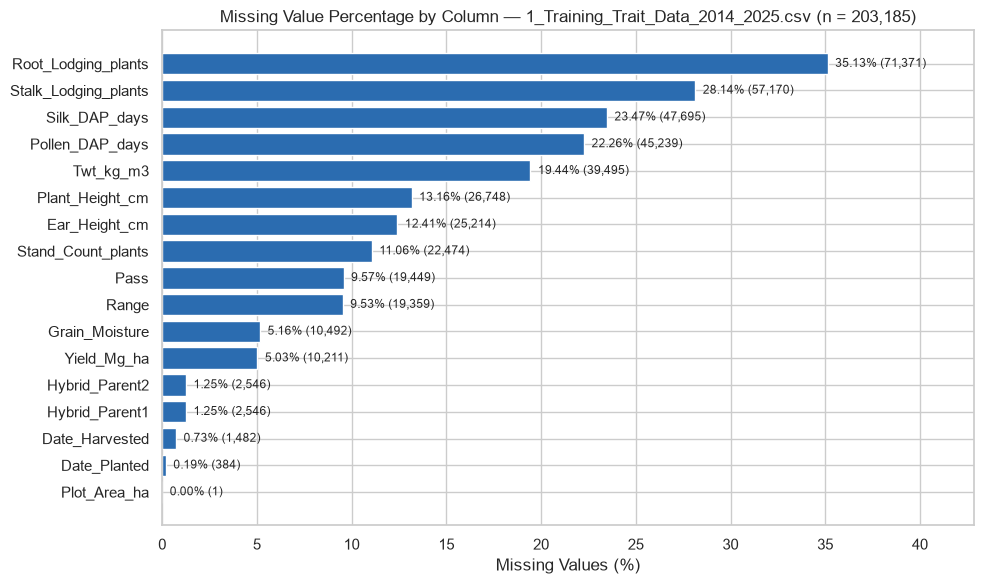

Saved figure: reports/figures/01_trait_missing_values.png


In [9]:
# Save aggregate missing-value visualization
plot_miss = missing_df[missing_df["missing_count"] > 0].sort_values("missing_pct", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(plot_miss["column"], plot_miss["missing_pct"], color="#2b6cb0", edgecolor="white")
ax.set_xlabel("Missing Values (%)")
ax.set_title("Missing Value Percentage by Column — 1_Training_Trait_Data_2014_2025.csv (n = 203,185)")
ax.set_xlim(0, max(plot_miss["missing_pct"]) * 1.22)

for bar, (_, row) in zip(bars, plot_miss.iterrows()):
    ax.text(
        bar.get_width() + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f"{row['missing_pct']:.2f}% ({int(row['missing_count']):,})",
        va="center",
        fontsize=8.5,
    )

plt.tight_layout()
fig_path_1 = FIGURES_DIR / "01_trait_missing_values.png"
fig.savefig(fig_path_1, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved figure: {fig_path_1.relative_to(PROJECT_ROOT).as_posix()}")

## 4. Target Variable Analysis (`Yield_Mg_ha`)

### Statistical concepts & ML relevance
- **Mean vs. Median & Skewness:** Comparing the mean and median alongside skewness tells us whether yield is roughly symmetric or skewed by crop failures (left tail) or high-yield outliers (right tail). This guides loss function choice and residual diagnostics.
- **Quartiles & IQR ($Q_3 - Q_1$):** The $1.5 \times \text{IQR}$ rule flags statistical tail observations (`< Q1 - 1.5*IQR` or `> Q3 + 1.5*IQR`). In agronomy, low yields frequently reflect genuine drought, flooding, disease, or lodging rather than data corruption, so flagged points are **documented, never automatically discarded**.
- **Percentiles (1st, 5th, 95th, 99th):** Quantify realistic empirical bounds for prediction sanity checks.

In [10]:
# Verify numeric parsing explicitly (check for any non-numeric strings if raw column were object)
raw_yield = df["Yield_Mg_ha"]
numeric_yield = pd.to_numeric(raw_yield, errors="coerce")
n_total = len(raw_yield)
n_missing_na = int(raw_yield.isna().sum())
n_non_numeric = int((raw_yield.notna() & numeric_yield.isna()).sum())
y = numeric_yield.dropna()

q01, q05, q25, q50, q75, q95, q99 = np.percentile(y, [1, 5, 25, 50, 75, 95, 99])
iqr = q75 - q25
lower_fence = q25 - 1.5 * iqr
upper_fence = q75 + 1.5 * iqr

n_zero = int((y == 0).sum())
n_negative = int((y < 0).sum())
n_low_outliers = int((y < lower_fence).sum())
n_high_outliers = int((y > upper_fence).sum())
n_total_outliers = n_low_outliers + n_high_outliers

target_stats = {
    "total_rows": n_total,
    "valid_numerical_observations": int(len(y)),
    "missing_observations_NaN": n_missing_na,
    "non_numeric_observations": n_non_numeric,
    "min": float(y.min()),
    "max": float(y.max()),
    "mean": float(y.mean()),
    "median": float(y.median()),
    "std": float(y.std(ddof=1)),
    "variance": float(y.var(ddof=1)),
    "p01": float(q01),
    "p05": float(q05),
    "q1_25": float(q25),
    "q2_50_median": float(q50),
    "q3_75": float(q75),
    "iqr": float(iqr),
    "p95": float(q95),
    "p99": float(q99),
    "skewness": float(y.skew()),
    "kurtosis_excess": float(y.kurt()),
    "zero_values": n_zero,
    "negative_values": n_negative,
    "iqr_lower_fence": float(lower_fence),
    "iqr_upper_fence": float(upper_fence),
    "iqr_low_outliers_count": n_low_outliers,
    "iqr_high_outliers_count": n_high_outliers,
    "iqr_total_outliers_count": n_total_outliers,
    "iqr_total_outliers_pct": float(n_total_outliers / len(y) * 100),
}

print("=== TARGET VARIABLE SUMMARY: Yield_Mg_ha ===")
for k, v in target_stats.items():
    if isinstance(v, float):
        print(f"  {k:<30}: {v:.4f}")
    else:
        print(f"  {k:<30}: {v:,}")

=== TARGET VARIABLE SUMMARY: Yield_Mg_ha ===
  total_rows                    : 203,185
  valid_numerical_observations  : 192,974
  missing_observations_NaN      : 10,211
  non_numeric_observations      : 0
  min                           : 0.4282
  max                           : 23.2680
  mean                          : 9.7504
  median                        : 9.9179
  std                           : 3.1278
  variance                      : 9.7829
  p01                           : 1.9562
  p05                           : 4.2781
  q1_25                         : 7.7062
  q2_50_median                  : 9.9179
  q3_75                         : 11.9271
  iqr                           : 4.2209
  p95                           : 14.6527
  p99                           : 16.5029
  skewness                      : -0.2164
  kurtosis_excess               : -0.1311
  zero_values                   : 0
  negative_values               : 0
  iqr_lower_fence               : 1.3748
  iqr_upper_fence  

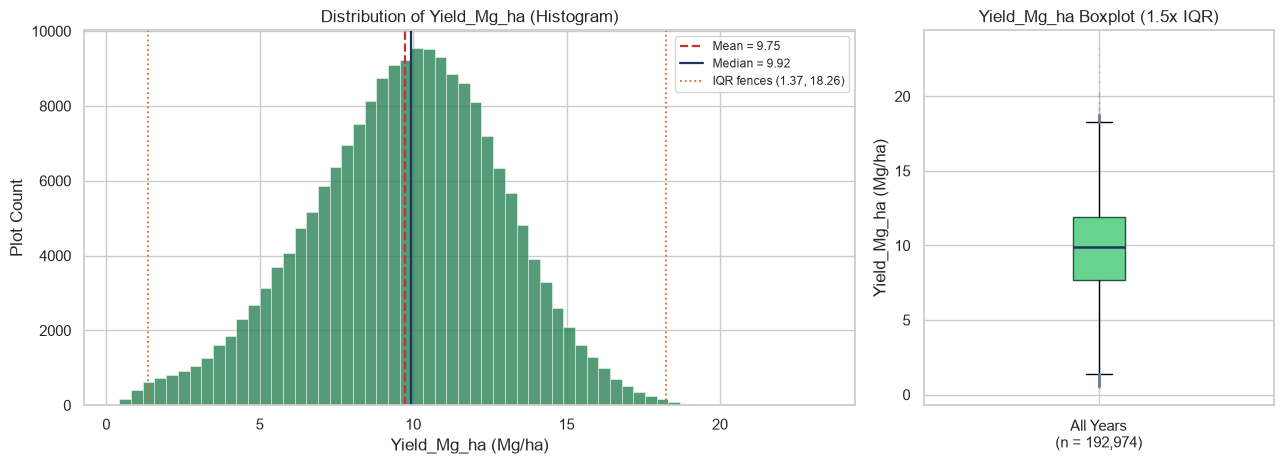

Saved figure: reports/figures/02_trait_yield_distribution.png


In [11]:
# Plot Yield histogram + boxplot side-by-side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})

axes[0].hist(y, bins=60, color="#2f855a", alpha=0.82, edgecolor="white", linewidth=0.4)
axes[0].axvline(y.mean(), color="#c53030", linestyle="--", linewidth=1.6, label=f"Mean = {y.mean():.2f}")
axes[0].axvline(y.median(), color="#1a365d", linestyle="-", linewidth=1.6, label=f"Median = {y.median():.2f}")
axes[0].axvline(lower_fence, color="#dd6b20", linestyle=":", linewidth=1.3, label=f"IQR fences ({lower_fence:.2f}, {upper_fence:.2f})")
axes[0].axvline(upper_fence, color="#dd6b20", linestyle=":", linewidth=1.3)
axes[0].set_title("Distribution of Yield_Mg_ha (Histogram)")
axes[0].set_xlabel("Yield_Mg_ha (Mg/ha)")
axes[0].set_ylabel("Plot Count")
axes[0].legend(frameon=True, fontsize=8.5)

axes[1].boxplot(
    y,
    orientation="vertical",
    patch_artist=True,
    boxprops=dict(facecolor="#68d391", color="#22543d"),
    medianprops=dict(color="#1a365d", linewidth=1.8),
    flierprops=dict(marker=".", markersize=2.5, alpha=0.35, markerfacecolor="#718096", markeredgecolor="none"),
)
axes[1].set_title("Yield_Mg_ha Boxplot (1.5x IQR)")
axes[1].set_ylabel("Yield_Mg_ha (Mg/ha)")
axes[1].set_xticks([1])
axes[1].set_xticklabels([f"All Years\n(n = {len(y):,})"])

plt.tight_layout()
fig_path_2 = FIGURES_DIR / "02_trait_yield_distribution.png"
fig.savefig(fig_path_2, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved figure: {fig_path_2.relative_to(PROJECT_ROOT).as_posix()}")

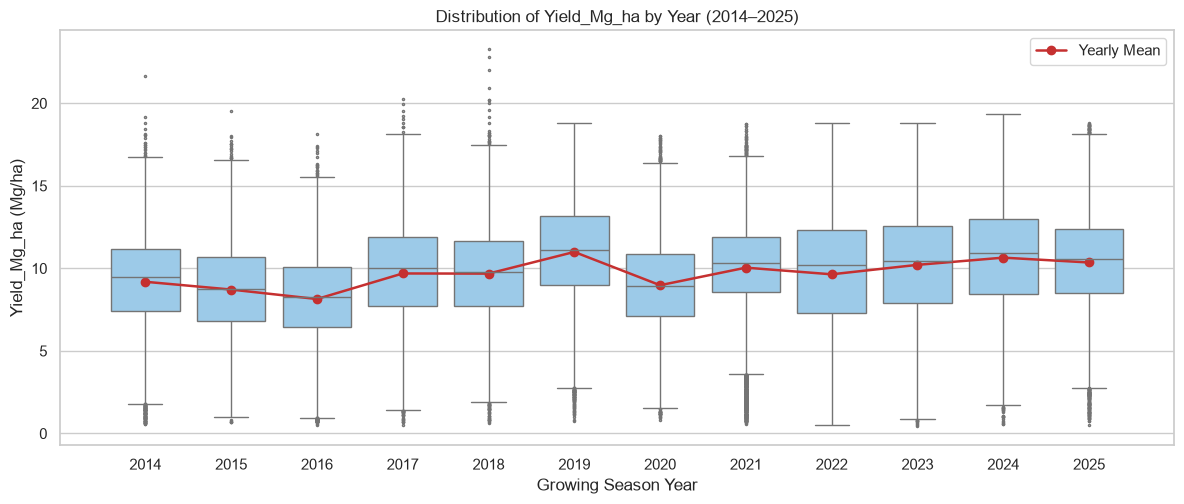

Saved figure: reports/figures/03_trait_yield_by_year.png


In [12]:
# Plot Yield distribution by Year (2014-2025)
valid_df = df.dropna(subset=["Yield_Mg_ha"])
years = sorted(valid_df["Year"].unique())
yearly_means = valid_df.groupby("Year")["Yield_Mg_ha"].mean().reindex(years)

fig, ax = plt.subplots(figsize=(12, 5.2))
sns.boxplot(
    data=valid_df,
    x="Year",
    y="Yield_Mg_ha",
    order=years,
    color="#90cdf4",
    fliersize=1.5,
    linewidth=1.0,
    ax=ax,
)
ax.plot(range(len(years)), yearly_means.values, color="#c53030", marker="o", linewidth=1.8, label="Yearly Mean")
ax.set_title("Distribution of Yield_Mg_ha by Year (2014–2025)")
ax.set_xlabel("Growing Season Year")
ax.set_ylabel("Yield_Mg_ha (Mg/ha)")
ax.legend(frameon=True)

plt.tight_layout()
fig_path_3 = FIGURES_DIR / "03_trait_yield_by_year.png"
fig.savefig(fig_path_3, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved figure: {fig_path_3.relative_to(PROJECT_ROOT).as_posix()}")

## 5. Observation Granularity, Experimental Replicates & Duplicate Audit

### Why this matters for machine learning
Agricultural field trials use **experimental replication**: the same maize `Hybrid` is intentionally planted in multiple field plots (`Replicate`, `Block`, `Plot`, `Range`, `Pass`) within the same `Env` to measure and reduce field spatial noise.
- **Genuine experimental replicates** share `(Env, Hybrid)` but differ in plot/spatial identifiers (`Replicate`, `Block`, `Plot`, `Range`, `Pass`). They are valid repeated measurements — **not** duplicate-data bugs!
- **Accidental duplicate records** would be identical rows or colliding plot-level keys.
- Understanding plot-level vs. `(Env, Hybrid)`-level granularity is also critical for **leakage-safe cross-validation** (replicates of the same `(Env, Hybrid)` or same `Env` must never be split randomly across train and validation folds!).

In [13]:
# Core identifier cardinality
id_cols = ["Env", "Year", "Field_Location", "Experiment", "Replicate", "Block", "Plot",
           "Range", "Pass", "Hybrid", "Hybrid_orig_name", "Hybrid_Parent1", "Hybrid_Parent2"]
print("=== IDENTIFIER CARDINALITY ===")
for c in id_cols:
    print(f"  {c:<18}: {df[c].nunique(dropna=True):>7,} unique (missing={int(df[c].isna().sum()):,})")

# Observation distribution summaries
obs_per_year = df.groupby("Year").size()
obs_per_env = df.groupby("Env").size()
obs_per_hybrid = df.groupby("Hybrid").size()

def dist_summary(s: pd.Series, name: str) -> dict:
    return {
        "group": name,
        "n_groups": int(len(s)),
        "min": int(s.min()),
        "p25": round(float(s.quantile(0.25)), 1),
        "median": round(float(s.median()), 1),
        "mean": round(float(s.mean()), 2),
        "p75": round(float(s.quantile(0.75)), 1),
        "max": int(s.max()),
    }

granularity_df = pd.DataFrame([
    dist_summary(obs_per_year, "Year"),
    dist_summary(obs_per_env, "Env"),
    dist_summary(obs_per_hybrid, "Hybrid"),
])
print("\n=== OBSERVATIONS PER GROUP SUMMARY ===")
print(granularity_df.to_string(index=False))

# Env x Hybrid granularity
eh_stats = df.groupby(["Env", "Hybrid"])["Yield_Mg_ha"].agg(
    n_obs="size",
    n_valid_yield="count",
)
n_eh_unique = len(eh_stats)
n_eh_multi = int((eh_stats["n_obs"] > 1).sum())
n_eh_single = int((eh_stats["n_obs"] == 1).sum())
n_eh_valid = int((eh_stats["n_valid_yield"] > 0).sum())
n_eh_no_valid = int((eh_stats["n_valid_yield"] == 0).sum())
n_eh_multi_valid = int((eh_stats["n_valid_yield"] > 1).sum())

print("\n=== (Env, Hybrid) COMBINATION GRANULARITY ===")
print(f"Unique (Env, Hybrid) combinations                     : {n_eh_unique:,}")
print(f"  - With exactly 1 observation                        : {n_eh_single:,} ({n_eh_single / n_eh_unique * 100:.2f}%)")
print(f"  - With multiple observations (replicated)           : {n_eh_multi:,} ({n_eh_multi / n_eh_unique * 100:.2f}%)")
print(f"  - With >= 1 valid Yield_Mg_ha label                 : {n_eh_valid:,} ({n_eh_valid / n_eh_unique * 100:.2f}%)")
print(f"  - With >= 2 valid Yield_Mg_ha labels                : {n_eh_multi_valid:,} ({n_eh_multi_valid / n_eh_unique * 100:.2f}%)")
print(f"  - With 0 valid Yield_Mg_ha labels (all NaN)         : {n_eh_no_valid:,} ({n_eh_no_valid / n_eh_unique * 100:.2f}%)")
print("Replication count distribution (top 10):", eh_stats["n_obs"].value_counts().sort_index().head(10).to_dict())
print("Max observations for a single (Env, Hybrid):", int(eh_stats["n_obs"].max()))

=== IDENTIFIER CARDINALITY ===
  Env               :     321 unique (missing=0)
  Year              :      12 unique (missing=0)
  Field_Location    :      46 unique (missing=0)
  Experiment        :      12 unique (missing=0)
  Replicate         :       4 unique (missing=0)
  Block             :      50 unique (missing=0)
  Plot              :   2,588 unique (missing=0)
  Range             :     124 unique (missing=19,359)
  Pass              :     286 unique (missing=19,449)
  Hybrid            :   6,203 unique (missing=0)
  Hybrid_orig_name  :   6,488 unique (missing=0)
  Hybrid_Parent1    :   2,695 unique (missing=2,546)
  Hybrid_Parent2    :      81 unique (missing=2,546)

=== OBSERVATIONS PER GROUP SUMMARY ===
 group  n_groups   min     p25  median     mean     p75   max
  Year        12 12675 14754.8 16236.5 16932.08 19346.0 20851
   Env       321    44   500.0   514.0   632.98   700.0  2065
Hybrid      6203     1    15.0    23.0    32.76    38.0  1018



=== (Env, Hybrid) COMBINATION GRANULARITY ===
Unique (Env, Hybrid) combinations                     : 132,635
  - With exactly 1 observation                        : 76,402 (57.60%)
  - With multiple observations (replicated)           : 56,233 (42.40%)
  - With >= 1 valid Yield_Mg_ha label                 : 128,597 (96.96%)
  - With >= 2 valid Yield_Mg_ha labels                : 52,392 (39.50%)
  - With 0 valid Yield_Mg_ha labels (all NaN)         : 4,038 (3.04%)
Replication count distribution (top 10): {1: 76402, 2: 49033, 3: 3414, 4: 2727, 5: 216, 6: 424, 7: 78, 8: 212, 9: 19, 10: 47}
Max observations for a single (Env, Hybrid): 37


In [14]:
# Exact duplicates and composite key audit
exact_dups = int(df.duplicated().sum())
print(f"Exact duplicate rows across all 26 columns: {exact_dups:,}")

candidate_keys = [
    ["Env", "Plot"],
    ["Env", "Experiment", "Plot"],
    ["Env", "Replicate", "Plot"],
    ["Env", "Replicate", "Block", "Plot"],
    ["Env", "Experiment", "Replicate", "Plot"],
    ["Env", "Experiment", "Replicate", "Block", "Plot"],
    ["Env", "Experiment", "Replicate", "Block", "Plot", "Range", "Pass"],
    ["Env", "Hybrid"],
    ["Env", "Hybrid", "Replicate"],
    ["Env", "Hybrid", "Replicate", "Block", "Plot"],
]

key_rows = []
for cols in candidate_keys:
    n_in_dup_groups = int(df.duplicated(subset=cols, keep=False).sum())
    n_extra = int(df.duplicated(subset=cols, keep="first").sum())
    key_rows.append({
        "candidate_key": " + ".join(cols),
        "is_unique": n_extra == 0,
        "extra_duplicate_rows": n_extra,
        "total_rows_in_dup_groups": n_in_dup_groups,
    })

print("\n=== CANDIDATE IDENTIFIER UNIQUENESS AUDIT ===")
print(pd.DataFrame(key_rows).to_string(index=False))

same_eh_rep_block = int(df.duplicated(subset=["Env", "Hybrid", "Replicate", "Block"], keep="first").sum())
print(f"\nRows sharing (Env, Hybrid, Replicate, Block) [different Plot IDs]: {same_eh_rep_block:,}")

Exact duplicate rows across all 26 columns: 0



=== CANDIDATE IDENTIFIER UNIQUENESS AUDIT ===
                                             candidate_key  is_unique  extra_duplicate_rows  total_rows_in_dup_groups
                                                Env + Plot      False                 33732                     62596
                                   Env + Experiment + Plot      False                 31091                     60497
                                    Env + Replicate + Plot      False                  5098                      9380
                            Env + Replicate + Block + Plot      False                   178                       326
                       Env + Experiment + Replicate + Plot      False                  1121                      2242
               Env + Experiment + Replicate + Block + Plot       True                     0                         0
Env + Experiment + Replicate + Block + Plot + Range + Pass       True                     0                         0
         

## 6. Temporal (2014–2025) & Environmental / Hybrid Variability Analysis

### Why this matters for machine learning
The competition requires forecasting **future 2026** hybrid–environment combinations, evaluated by **average within-environment Pearson correlation ($r$)**.
- **Temporal analysis** reveals year-to-year shifts in trial scale, hybrid turnover, and macro-climate yield levels.
- **Between-environment vs. within-environment variance** reveals how much yield variation comes from *where/when* corn is grown (environment main effect) vs. *which hybrid* outperforms peers *within* an environment (genetic + G × E signal — the exact component scored by within-environment Pearson $r$!).

In [15]:
# Per-year comprehensive table (2014-2025)
yearly_summary = (
    df.groupby("Year")
    .agg(
        n_obs=("Yield_Mg_ha", "size"),
        valid_yield_n=("Yield_Mg_ha", "count"),
        missing_yield_n=("Yield_Mg_ha", lambda s: int(s.isna().sum())),
        n_envs=("Env", "nunique"),
        n_locations=("Field_Location", "nunique"),
        n_hybrids=("Hybrid", "nunique"),
        yield_mean=("Yield_Mg_ha", "mean"),
        yield_median=("Yield_Mg_ha", "median"),
        yield_std=("Yield_Mg_ha", "std"),
    )
    .assign(missing_yield_pct=lambda d: (d["missing_yield_n"] / d["n_obs"] * 100).round(2))
)

cols_order = [
    "n_obs", "valid_yield_n", "missing_yield_pct", "n_envs", "n_locations",
    "n_hybrids", "yield_mean", "yield_median", "yield_std"
]
print("=== TEMPORAL COVERAGE & YIELD SUMMARY BY YEAR (2014-2025) ===")
print(yearly_summary[cols_order].round(3).to_string())

expected_years = set(range(2014, 2026))
observed_years = set(df["Year"].unique())
print(f"\nAll years 2014-2025 present : {expected_years == observed_years}")
print(f"Missing years from 2014-2025: {sorted(expected_years - observed_years)}")
print(f"Unexpected years outside    : {sorted(observed_years - expected_years)}")

=== TEMPORAL COVERAGE & YIELD SUMMARY BY YEAR (2014-2025) ===
      n_obs  valid_yield_n  missing_yield_pct  n_envs  n_locations  n_hybrids  yield_mean  yield_median  yield_std
Year                                                                                                              
2014  12675          11593               8.54      24           24        882       9.189         9.486      2.795
2015  13688          13219               3.43      27           27       1210       8.718         8.776      2.868
2016  15387          14452               6.08      27           27        645       8.143         8.267      2.770
2017  15533          12828              17.41      30           30        579       9.692        10.015      3.069
2018  20851          20377               2.27      29           28       1076       9.683         9.759      2.739
2019  20806          19876               4.47      28           28       1207      10.996        11.088      3.002
2020  16940       

In [16]:
# Yield variability across environments and hybrids (valid yield rows only)
valid_df = df.dropna(subset=["Yield_Mg_ha"])

env_yield = valid_df.groupby("Env")["Yield_Mg_ha"].agg(
    n_valid="count", mean="mean", median="median", std="std"
)
hyb_meta = valid_df.groupby("Hybrid").agg(
    n_valid=("Yield_Mg_ha", "count"),
    n_envs=("Env", "nunique"),
    n_years=("Year", "nunique"),
    mean=("Yield_Mg_ha", "mean"),
    median=("Yield_Mg_ha", "median"),
    std=("Yield_Mg_ha", "std"),
)

# Variance decomposition: Total Variance = Between-Env Variance + Within-Env Variance (law of total variance)
grand_mean = valid_df["Yield_Mg_ha"].mean()
total_var = float(valid_df["Yield_Mg_ha"].var(ddof=0))
env_means_mapped = valid_df["Env"].map(env_yield["mean"])
between_env_var = float(((env_means_mapped - grand_mean) ** 2).mean())
within_env_var = float(((valid_df["Yield_Mg_ha"] - env_means_mapped) ** 2).mean())

print("=== ENVIRONMENT-LEVEL YIELD VARIABILITY ===")
print(f"Environments with >= 1 valid yield: {len(env_yield):,} (out of {df['Env'].nunique():,} total)")
print(env_yield[["n_valid", "mean", "median", "std"]].describe().round(3).to_string())

print("\n=== VARIANCE DECOMPOSITION (PLOT-LEVEL Yield_Mg_ha) ===")
print(f"Total variance              : {total_var:.4f}")
print(f"Between-environment variance: {between_env_var:.4f} ({between_env_var / total_var * 100:.2f}%)")
print(f"Within-environment variance : {within_env_var:.4f} ({within_env_var / total_var * 100:.2f}%)")

print("\n=== HYBRID-LEVEL YIELD VARIABILITY ===")
print(f"Hybrids with >= 1 valid yield : {len(hyb_meta):,} (out of {df['Hybrid'].nunique():,} total)")
print(f"Hybrids tested in > 1 year    : {int((hyb_meta['n_years'] > 1).sum()):,} ({(hyb_meta['n_years'] > 1).mean() * 100:.2f}%)")
print(f"Hybrids tested in >= 10 plots : {int((hyb_meta['n_valid'] >= 10).sum()):,} ({(hyb_meta['n_valid'] >= 10).mean() * 100:.2f}%)")
print(hyb_meta[["n_valid", "n_envs", "n_years", "mean", "std"]].describe().round(3).to_string())

=== ENVIRONMENT-LEVEL YIELD VARIABILITY ===
Environments with >= 1 valid yield: 321 (out of 321 total)
        n_valid     mean   median      std
count   321.000  321.000  321.000  321.000
mean    601.165    9.514    9.613    1.963
std     286.625    2.511    2.571    0.485
min      38.000    1.445    1.361    0.350
25%     483.000    8.043    8.123    1.699
50%     498.000    9.767    9.898    1.959
75%     668.000   11.189   11.415    2.220
max    2053.000   15.051   15.149    3.696

=== VARIANCE DECOMPOSITION (PLOT-LEVEL Yield_Mg_ha) ===
Total variance              : 9.7828
Between-environment variance: 5.6125 (57.37%)
Within-environment variance : 4.1703 (42.63%)

=== HYBRID-LEVEL YIELD VARIABILITY ===
Hybrids with >= 1 valid yield : 6,024 (out of 6,203 total)
Hybrids tested in > 1 year    : 4,307 (71.50%)
Hybrids tested in >= 10 plots : 5,236 (86.92%)
        n_valid    n_envs   n_years      mean       std
count  6024.000  6024.000  6024.000  6024.000  5992.000
mean     32.034    

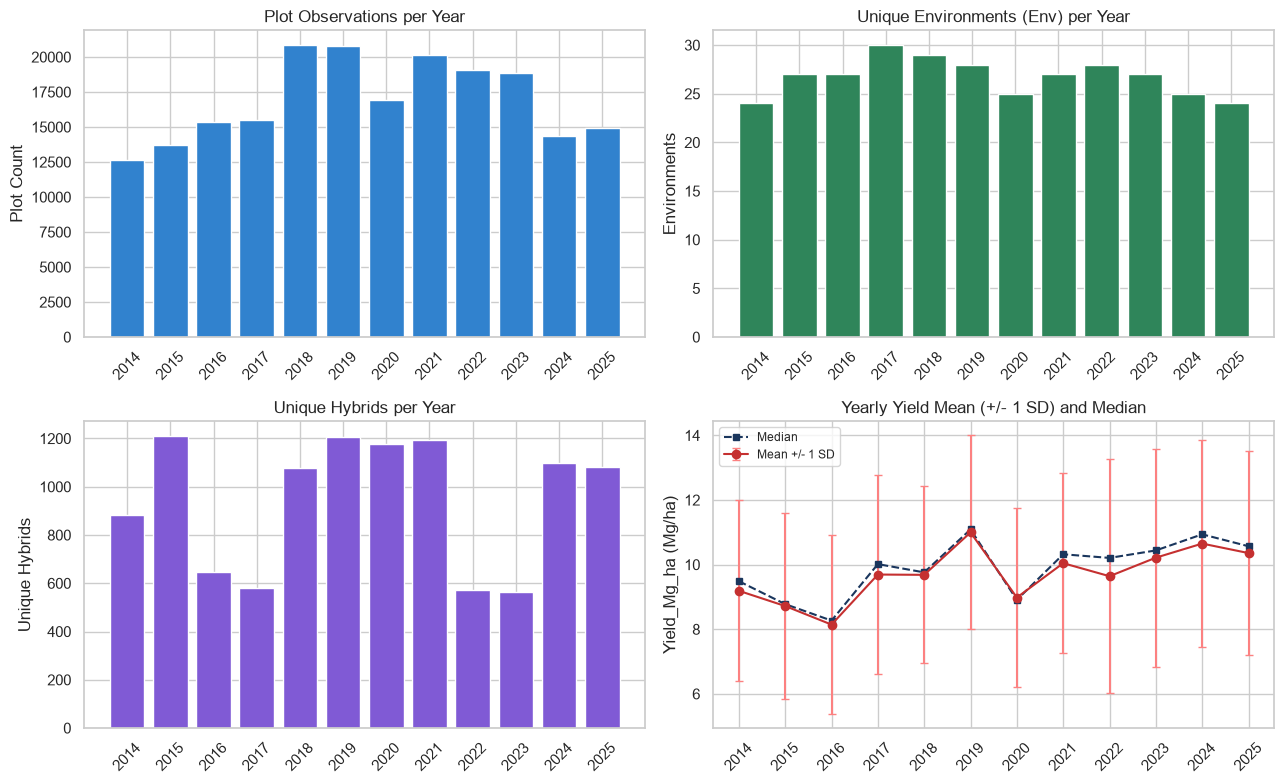

Saved figure: reports/figures/04_trait_temporal_coverage.png


In [17]:
# Temporal coverage & yearly yield trend visualization
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
yrs = yearly_summary.index.values

axes[0, 0].bar(yrs, yearly_summary["n_obs"], color="#3182ce", edgecolor="white")
axes[0, 0].set_title("Plot Observations per Year")
axes[0, 0].set_ylabel("Plot Count")
axes[0, 0].set_xticks(yrs)
axes[0, 0].tick_params(axis="x", rotation=45)

axes[0, 1].bar(yrs, yearly_summary["n_envs"], color="#2f855a", edgecolor="white")
axes[0, 1].set_title("Unique Environments (Env) per Year")
axes[0, 1].set_ylabel("Environments")
axes[0, 1].set_xticks(yrs)
axes[0, 1].tick_params(axis="x", rotation=45)

axes[1, 0].bar(yrs, yearly_summary["n_hybrids"], color="#805ad5", edgecolor="white")
axes[1, 0].set_title("Unique Hybrids per Year")
axes[1, 0].set_ylabel("Unique Hybrids")
axes[1, 0].set_xticks(yrs)
axes[1, 0].tick_params(axis="x", rotation=45)

axes[1, 1].errorbar(
    yrs,
    yearly_summary["yield_mean"],
    yerr=yearly_summary["yield_std"],
    fmt="-o",
    color="#c53030",
    ecolor="#fc8181",
    capsize=3,
    label="Mean +/- 1 SD",
)
axes[1, 1].plot(yrs, yearly_summary["yield_median"], "--s", color="#1a365d", markersize=4, label="Median")
axes[1, 1].set_title("Yearly Yield Mean (+/- 1 SD) and Median")
axes[1, 1].set_ylabel("Yield_Mg_ha (Mg/ha)")
axes[1, 1].set_xticks(yrs)
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].legend(frameon=True, fontsize=8.5)

plt.tight_layout()
fig_path_4 = FIGURES_DIR / "04_trait_temporal_coverage.png"
fig.savefig(fig_path_4, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved figure: {fig_path_4.relative_to(PROJECT_ROOT).as_posix()}")

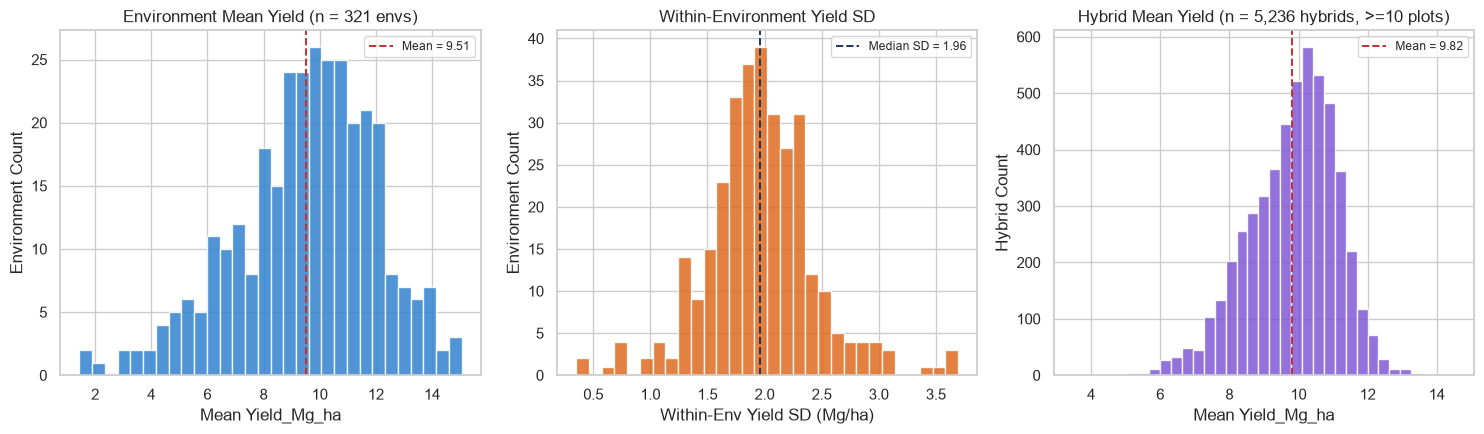

Saved figure: reports/figures/05_trait_env_hybrid_variability.png


In [18]:
# Environment-level and hybrid-level yield variability visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].hist(env_yield["mean"], bins=30, color="#3182ce", alpha=0.85, edgecolor="white")
axes[0].axvline(
    env_yield["mean"].mean(),
    color="#c53030",
    linestyle="--",
    linewidth=1.4,
    label=f"Mean = {env_yield['mean'].mean():.2f}",
)
axes[0].set_title(f"Environment Mean Yield (n = {len(env_yield)} envs)")
axes[0].set_xlabel("Mean Yield_Mg_ha")
axes[0].set_ylabel("Environment Count")
axes[0].legend(fontsize=8.5)

axes[1].hist(env_yield["std"].dropna(), bins=30, color="#dd6b20", alpha=0.85, edgecolor="white")
axes[1].axvline(
    env_yield["std"].median(),
    color="#1a365d",
    linestyle="--",
    linewidth=1.4,
    label=f"Median SD = {env_yield['std'].median():.2f}",
)
axes[1].set_title("Within-Environment Yield SD")
axes[1].set_xlabel("Within-Env Yield SD (Mg/ha)")
axes[1].set_ylabel("Environment Count")
axes[1].legend(fontsize=8.5)

hyb_10 = hyb_meta[hyb_meta["n_valid"] >= 10]
axes[2].hist(hyb_10["mean"], bins=35, color="#805ad5", alpha=0.85, edgecolor="white")
axes[2].axvline(
    hyb_10["mean"].mean(),
    color="#c53030",
    linestyle="--",
    linewidth=1.4,
    label=f"Mean = {hyb_10['mean'].mean():.2f}",
)
axes[2].set_title(f"Hybrid Mean Yield (n = {len(hyb_10):,} hybrids, >=10 plots)")
axes[2].set_xlabel("Mean Yield_Mg_ha")
axes[2].set_ylabel("Hybrid Count")
axes[2].legend(fontsize=8.5)

plt.tight_layout()
fig_path_5 = FIGURES_DIR / "05_trait_env_hybrid_variability.png"
fig.savefig(fig_path_5, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved figure: {fig_path_5.relative_to(PROJECT_ROOT).as_posix()}")

## 7. Preliminary Data Leakage Assessment

### Why this matters for machine learning
**Target / temporal leakage** happens whenever a model receives inputs during training that are measured *at harvest*, *during the growing season as plot-level outcomes*, or otherwise *absent from the 2026 test set*. A column that correlates strongly with `Yield_Mg_ha` (such as `Grain_Moisture`, `Twt_kg_m3`, or `Plant_Height_cm`) is often **a co-measured outcome of the same crop growth**, NOT a legitimate input feature for predicting 2026 yield.

Below we conservatively classify every single column in `1_Training_Trait_Data_2014_2025.csv`. **No column is automatically approved for modeling** — final feature eligibility will only be confirmed after inspecting the 2026 testing files and metadata in subsequent phases.

In [19]:
leakage_classification = [
    ("Yield_Mg_ha", "Target variable", "Official competition prediction target (Mg/ha at 15.5% moisture). Never an input feature."),
    ("Env", "Identifiers", "Environment key (location + year). Join key for weather/soil/EC/metadata and CV grouping key."),
    ("Year", "Identifiers", "Temporal season key (2014-2025). Critical for temporal CV splits; not a stationary predictor alone."),
    ("Field_Location", "Identifiers", "Location identifier; potential prediction-time context if confirmed in 2026 test metadata."),
    ("Experiment", "Identifiers", "Trial series identifier; check whether present/consistent in 2026 test metadata."),
    ("Replicate", "Identifiers", "Field-trial replication index (plot-level experimental design)."),
    ("Block", "Identifiers", "Field-trial block index (plot-level experimental design)."),
    ("Plot", "Identifiers", "Plot ID within trial/replicate/block (pure spatial/experimental identifier)."),
    ("Range", "Identifiers", "Field spatial grid row coordinate (plot-level layout; check if absent in 2026 submission template)."),
    ("Pass", "Identifiers", "Field spatial grid column coordinate (plot-level layout; check if absent in 2026 submission template)."),
    ("Hybrid", "Identifiers", "Standardized hybrid ID. Join key to genomic datasets and potential grouping/entity identifier."),
    ("Hybrid_orig_name", "Identifiers", "Unstandardized field hybrid name; check consistency/availability in 2026 test inputs."),
    ("Hybrid_Parent1", "Potential prediction-time features", "Parental inbred lineage; potentially available or derivable from Hybrid/genotype data (verify against 2026 test set)."),
    ("Hybrid_Parent2", "Potential prediction-time features", "Parental inbred/tester lineage; potentially available or derivable from Hybrid/genotype data (verify against 2026 test set)."),
    ("Plot_Area_ha", "Unknown availability requiring investigation", "Management/design parameter; likely plot-level and unavailable in 2026 test template (verify in Phase 2.3+)."),
    ("Date_Planted", "Unknown availability requiring investigation", "Pre-season management date; useful for weather-window alignment ONLY if provided in 2026 test metadata."),
    ("Date_Harvested", "Potential post-harvest or outcome-derived features", "Recorded at harvest; reflects crop maturity/drydown/harvest logistics. Severe leakage risk unless explicitly given at test time (unlikely)."),
    ("Grain_Moisture", "Potential post-harvest or outcome-derived features", "Measured at harvest directly on harvested grain (and used to moisture-adjust yield). Severe post-harvest leakage."),
    ("Twt_kg_m3", "Potential post-harvest or outcome-derived features", "Grain test weight measured on harvested grain. Severe post-harvest leakage."),
    ("Stand_Count_plants", "Potential post-harvest or outcome-derived features", "In-season plot-level emergence phenotype measured after planting; outcome-derived and typically unavailable in 2026 test inputs."),
    ("Pollen_DAP_days", "Potential post-harvest or outcome-derived features", "In-season flowering phenotype measured on plants; outcome-derived and typically unavailable as a 2026 test input."),
    ("Silk_DAP_days", "Potential post-harvest or outcome-derived features", "In-season flowering phenotype measured on plants; outcome-derived and typically unavailable as a 2026 test input."),
    ("Plant_Height_cm", "Potential post-harvest or outcome-derived features", "In-season vegetative phenotype measured on plants; outcome-derived and typically unavailable as a 2026 test input."),
    ("Ear_Height_cm", "Potential post-harvest or outcome-derived features", "In-season morphological phenotype measured on plants; outcome-derived and typically unavailable as a 2026 test input."),
    ("Root_Lodging_plants", "Potential post-harvest or outcome-derived features", "Late-season/pre-harvest stress outcome measured on plots; severe leakage if used as a direct input."),
    ("Stalk_Lodging_plants", "Potential post-harvest or outcome-derived features", "Late-season/pre-harvest stress outcome measured on plots; severe leakage if used as a direct input."),
]

leakage_df = pd.DataFrame(leakage_classification, columns=["column", "category", "rationale"])
assert set(leakage_df["column"]) == set(df.columns), "All 26 columns must be classified!"
print("=== PRELIMINARY LEAKAGE CLASSIFICATION (ALL 26 COLUMNS) ===")
for cat, grp in leakage_df.groupby("category", sort=False):
    print(f"  {cat} ({len(grp)}): {list(grp['column'])}")
print("\nDetailed Table:")
print(leakage_df.to_string(index=False))

=== PRELIMINARY LEAKAGE CLASSIFICATION (ALL 26 COLUMNS) ===
  Target variable (1): ['Yield_Mg_ha']
  Identifiers (11): ['Env', 'Year', 'Field_Location', 'Experiment', 'Replicate', 'Block', 'Plot', 'Range', 'Pass', 'Hybrid', 'Hybrid_orig_name']
  Potential prediction-time features (2): ['Hybrid_Parent1', 'Hybrid_Parent2']
  Unknown availability requiring investigation (2): ['Plot_Area_ha', 'Date_Planted']
  Potential post-harvest or outcome-derived features (10): ['Date_Harvested', 'Grain_Moisture', 'Twt_kg_m3', 'Stand_Count_plants', 'Pollen_DAP_days', 'Silk_DAP_days', 'Plant_Height_cm', 'Ear_Height_cm', 'Root_Lodging_plants', 'Stalk_Lodging_plants']

Detailed Table:
              column                                           category                                                                                                                                   rationale
         Yield_Mg_ha                                    Target variable                                          

## 8. Confirmed Findings vs. Unresolved Technical Questions

### Confirmed Findings (Verified Empirically on `1_Training_Trait_Data_2014_2025.csv`)
- **Dataset Scale & Memory:** `203,185` rows × `26` columns; loads rapidly (`< 1 s`) using Pandas' C engine (`~58.65 MB` deep RAM).
- **Complete Temporal Coverage:** All 12 growing seasons from `2014` through `2025` are present.
- **Plot-Level Granularity with Experimental Replication:** `0` exact duplicate rows exist, and `(Env, Experiment, Replicate, Block, Plot)` uniquely identifies all `203,185` plots. Meanwhile, `(Env, Hybrid)` combinations are frequently replicated across plots (genuine experimental replicates).
- **Target Distribution & Variance Structure:** `Yield_Mg_ha` has `192,974` valid observations (`5.03%` missing, `0` negative, `0` zero, `0` non-numeric), mean `9.7504 Mg/ha`, median `9.9179 Mg/ha`, SD `3.1278 Mg/ha`, and skewness `-0.2164`. Plot-level variance decomposes into **57.37% between-environment** and **42.63% within-environment**, underscoring the importance of modeling within-environment hybrid ranking for the competition's within-environment Pearson $r$ metric.
- **High Leakage Risk in Co-Measured Traits:** 10 agronomic/harvest columns (`Date_Harvested`, `Grain_Moisture`, `Twt_kg_m3`, `Stand_Count_plants`, `Pollen_DAP_days`, `Silk_DAP_days`, `Plant_Height_cm`, `Ear_Height_cm`, `Root_Lodging_plants`, `Stalk_Lodging_plants`) represent in-season or post-harvest measurements and must **not** be used as direct input features.

### Unresolved Technical Questions & Proposed Decisions (For Phase 2.3+ / Phase 3)
1. **Official Data Dictionary Verification:** Confirm inferred meanings and units for the 25 non-target columns against official G2F documentation.
2. **2026 Test Schema Confirmation:** Verify exact columns available in the 2026 testing metadata and submission template (e.g., whether `Date_Planted`, `Field_Location`, `Hybrid_Parent1/2`, or `Plot_Area_ha` are supplied for 2026).
3. **Training Target Aggregation vs. Plot-Level Modeling:** Decide in Phase 3 whether to train on plot-level records (`192,974` valid plots) or `(Env, Hybrid)` mean/BLUP yield labels (`128,597` valid combinations, excluding `4,038` combinations with 0 valid yield labels).
4. **High-Missingness Environments & Extreme Values Policy:** Decide how to treat high-missingness environments (e.g., `SCH1_2024` at `78.40%` missing targets; `2017` at `17.41%` missing) and inspect extreme low/high `Yield_Mg_ha` (`982` IQR-flagged plots, `0.51%`), `Grain_Moisture`, or `Twt_kg_m3` values against metadata/weather notes before finalizing modeling pipelines.
5. **Auxiliary Multi-Task Use of In-Season Traits:** Optionally investigate in later phases whether in-season traits (`Plant_Height_cm`, `Pollen_DAP_days`, `Silk_DAP_days`, `Grain_Moisture`) add value strictly as **auxiliary training targets** (never test-time inputs).